# Final results: measured accuracy and new-policy simulation
Read the frozen predictions, then open the three reserved human-answer questions. No model changes follow this evaluation. New policy questions have no human ground truth.

In [1]:
import os, json, hashlib, base64, html
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
OUT=ROOT / "outputs"; FIGURES=OUT / "figures"
os.environ["MPLCONFIGDIR"]=str(ROOT / ".cache/matplotlib")
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import FancyBboxPatch
get_ipython().run_line_magic("matplotlib", "inline")
def read_json(name): return json.loads((ROOT / name).read_text())
def sha(name):
    with (ROOT / name).open("rb") as f: return hashlib.file_digest(f,"sha256").hexdigest()
def save_json(name,obj): (ROOT / name).write_text(json.dumps(obj,indent=2)+"\n")
seal=read_json("outputs/final_prediction_seal.json")
assert seal["final_test_predictions_frozen"] and not seal["final_test_answers_loaded"]
for name,digest in {**seal["input_sha256"],**seal["prediction_sha256"]}.items(): assert sha(name) == digest, name
protocol=read_json("configs/final_simulation_protocol.json")
survey=read_json("configs/energy_policy_survey.json")
items={q["item_id"]:q for q in read_json("data/processed/question_bank.json")["items"]}
with np.load(OUT / "final_test_predictions.npz",allow_pickle=False) as f:
    pids,ids,qids,p,pop,zero=[f[k].copy() for k in ["person_ids","persona_ids","item_ids","probabilities","population_probabilities","zero_vector_probabilities"]]
with np.load(OUT / "novel_policy_predictions.npz",allow_pickle=False) as f:
    assert np.array_equal(f["person_ids"],pids)
    new_qids,new_p,new_pop,new_zero,samples=[f[k].copy() for k in ["item_ids","probabilities","population_probabilities","zero_vector_probabilities","sampled_response_codes"]]
assert new_qids.tolist() == [q["item_id"] for q in survey["questions"]]
# First final evaluation: only after prediction and configuration hashes are verified.
spec=next(s for s in read_json("data/splits/partition_manifest.json")["partitions"] if s["partition"] == "final_test")
assert sha(spec["path"]) == spec["sha256"]
truth=pd.read_parquet(ROOT / spec["path"])
assert truth.pid.tolist() == pids.tolist() and truth.columns.tolist() == ["pid"]+qids.tolist()
y=truth[qids.tolist()].to_numpy(dtype=int)-1
assert y.shape == (100,3) and ((y >= 0) & (y < 5)).all()
people=np.arange(100)[:,None]; questions=np.arange(3)[None,:]
human=np.stack([(y == k).mean(0) for k in range(5)],axis=-1)
def loss(pred): return -np.log(np.clip(pred[people,questions,y],1e-12,1))
def hit(pred): return pred.argmax(-1) == y
def metrics(pred):
    losses=loss(pred); correct=hit(pred); shares=pred.mean(0)
    tv=np.abs(shares-human).sum(-1)/2
    support=shares[:,3:].sum(-1); human_support=human[:,3:].sum(-1)
    return {"nll":float(losses.mean()),"accuracy":float(correct.mean()),"distribution_TV":float(tv.mean()),
            "support_share_mae":float(np.abs(support-human_support).mean()),
            "per_question":[{"item_id":str(q),"accuracy":float(correct[:,j].mean()),"nll":float(losses[:,j].mean()),
              "distribution_TV":float(tv[j]),"human_shares":human[j].tolist(),"predicted_shares":shares[j].tolist(),
              "human_support":float(human_support[j]),"predicted_support":float(support[j])} for j,q in enumerate(qids)]}
predictions={"100 personas":p,"Population baseline":pop,"Shared model only":zero}
results={name:metrics(pred) for name,pred in predictions.items()}
rng=np.random.default_rng(protocol["seed"])
bootstrap={}
for name in ["Population baseline","Shared model only"]:
    differences=np.column_stack([(hit(p).astype(float)-hit(predictions[name])).mean(1), (loss(p)-loss(predictions[name])).mean(1)])
    distribution=differences[rng.integers(0,100,size=(3000,100))].mean(1)
    bootstrap[name]={metric:{"personas_minus_comparator":float(differences[:,j].mean()),
                            "paired_respondent_bootstrap_95":np.quantile(distribution[:,j],[.025,.975]).tolist()}
                     for j,metric in enumerate(["accuracy","nll"])}
new_results=[]
for j,q in enumerate(survey["questions"]):
    shares=new_p[:,j].mean(0); support=new_p[:,j,3:].sum(-1)
    sample_counts=np.bincount(samples[:,j],minlength=6)[1:]
    new_results.append({"item_id":q["item_id"],"label":q["short_label"],"expected_shares":shares.tolist(),
      "expected_support":float(support.mean()),"population_support":float(new_pop[:,j,3:].sum(-1).mean()),
      "zero_vector_support":float(new_zero[:,j,3:].sum(-1).mean()),"sampled_counts":sample_counts.tolist(),
      "persona_support_range": [float(support.min()),float(support.max())]})
final_report={"evaluated_utc":datetime.now(timezone.utc).isoformat(),"model":protocol["selected_model"],"personas":100,
      "test_questions":qids.tolist(),"observed_test_answers":int(y.size),"metrics":results,"paired_bootstrap":bootstrap,
      "new_question_results":new_results,"prediction_seal_sha256":sha("outputs/final_prediction_seal.json"),
      "test_labels_sha256":spec["sha256"],"test_label_file":spec["path"],
      "final_test_answers_loaded":True,"retest_reference_loaded":False,"model_changed_after_test":False,
      "limitations":protocol["limitations"]+["Bootstrap resamples people on three fixed questions; it excludes question and model-selection uncertainty."]}
save_json("outputs/final_evaluation.json",final_report)
display(pd.DataFrame(results).T.drop(columns="per_question").astype(float).round(4))
display(pd.DataFrame(new_results)[["label","expected_support","population_support","zero_vector_support"]].round(4))
print("Final test evaluated with frozen predictions. No model change or reselection.")

,nll,accuracy,distribution_TV,support_share_mae
100 personas,1.3010,0.4633,0.1487,0.0697
Population baseline,1.4309,0.3233,0.1457,0.0703
Shared model only,1.4262,0.3233,0.1478,0.0260


,label,expected_support,population_support,zero_vector_support
0,100% credits / 0% improvements,0.6112,0.623,0.6717
1,75% credits / 25% improvements,0.6183,0.623,0.6764
2,50% credits / 50% improvements,0.6153,0.623,0.6687
3,25% credits / 75% improvements,0.6186,0.623,0.6742
4,0% credits / 100% improvements,0.6164,0.623,0.6743


Final test evaluated with frozen predictions. No model change or reselection.


## How the simulation works
The LLM supplies the meaning of each question/answer. The small learned response model combines those features with each person's vector to predict five probabilities. Sampling once gives a single-select answer; averaging probabilities gives the stable aggregate estimate.

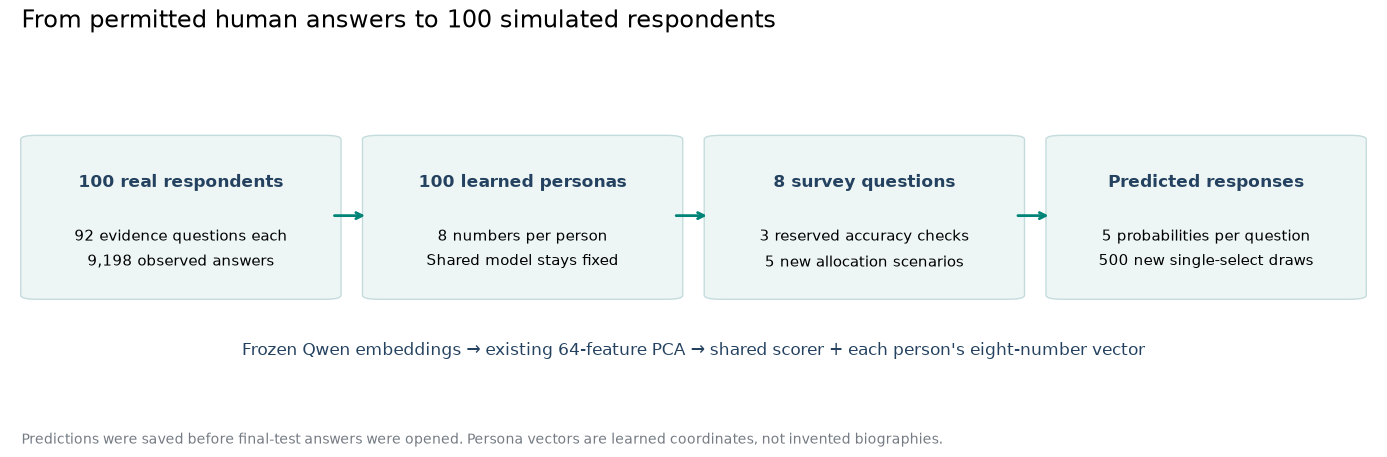

In [2]:
NAVY,TEAL,GREY="#244260","#008477","#747B83"
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11,"axes.titlesize":13,"axes.labelsize":11,
 "axes.spines.top":False,"axes.spines.right":False,"axes.edgecolor":"#CAD1D8","grid.color":"#E8ECF0",
 "figure.facecolor":"white","axes.facecolor":"white","pdf.fonttype":42})
exports=[]
def save_figure(fig,name):
    for ext in ["png","pdf"]:
        path=FIGURES / f"{name}.{ext}"
        fig.savefig(path,dpi=180,bbox_inches="tight",facecolor="white")
        exports.append({"path":str(path.relative_to(ROOT)),"sha256":sha(str(path.relative_to(ROOT)))})
    display(fig);plt.close(fig)
fig,ax=plt.subplots(figsize=(14,4.5));ax.axis("off");ax.set_xlim(-.01,1.01);ax.set_ylim(0,1)
boxes=[(.01,"100 real respondents","92 evidence questions each\n9,198 observed answers"),
       (.265,"100 learned personas","8 numbers per person\nShared model stays fixed"),
       (.52,"8 survey questions","3 reserved accuracy checks\n5 new allocation scenarios"),
       (.775,"Predicted responses","5 probabilities per question\n500 new single-select draws")]
for x,title,body in boxes:
    ax.add_patch(FancyBboxPatch((x,.35),.215,.47,boxstyle="round,pad=0.012",facecolor="#EDF5F5",edgecolor="#C5DCDD"))
    ax.text(x+.1075,.69,title,ha="center",va="center",fontsize=12,fontweight="bold",color=NAVY)
    ax.text(x+.1075,.49,body,ha="center",va="center",fontsize=11,linespacing=1.6)
for x in [.235,.49,.745]: ax.annotate("",xy=(x+.022,.59),xytext=(x-.005,.59),arrowprops={"arrowstyle":"->","color":TEAL,"lw":2})
ax.text(.5,.17,"Frozen Qwen embeddings → existing 64-feature PCA → shared scorer + each person's eight-number vector",ha="center",fontsize=12,color=NAVY)
fig.suptitle("From permitted human answers to 100 simulated respondents",x=.02,ha="left",fontsize=17)
fig.text(.02,.015,"Predictions were saved before final-test answers were opened. Persona vectors are learned coordinates, not invented biographies.",fontsize=10,color=GREY)
fig.tight_layout(rect=(0,.05,1,.95));save_figure(fig,"06_final_persona_pipeline")

## Reserved human-answer test
Compare predictions with the 100 respondents' real answers on three unseen energy-policy questions. Bars show mean probabilities, not the random simulated draws. The baseline uses training data only.

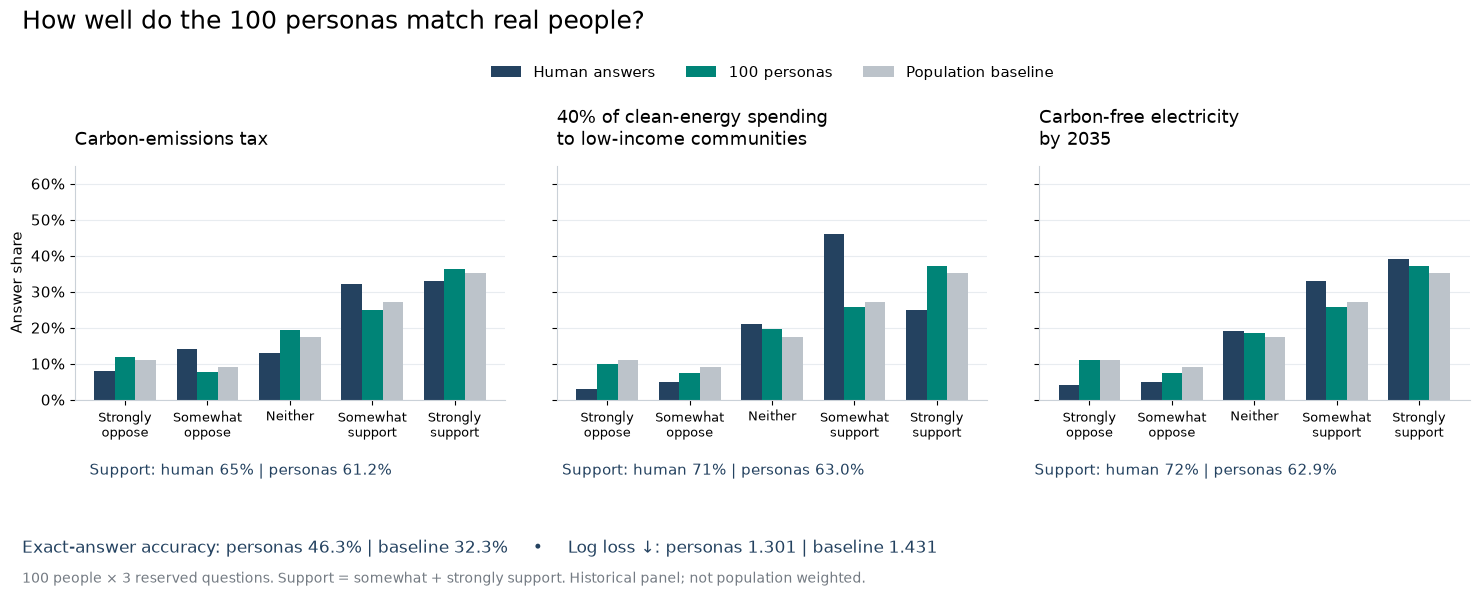

In [3]:
titles=["Carbon-emissions tax","40% of clean-energy spending\nto low-income communities","Carbon-free electricity\nby 2035"]
option_labels=["Strongly\noppose","Somewhat\noppose","Neither","Somewhat\nsupport","Strongly\nsupport"]
fig,axes=plt.subplots(1,3,figsize=(15,6),sharey=True)
for j,ax in enumerate(axes):
    x=np.arange(5);width=.25
    ax.bar(x-width,human[j],width,color=NAVY,label="Human answers")
    ax.bar(x,p[:,j].mean(0),width,color=TEAL,label="100 personas")
    ax.bar(x+width,pop[:,j].mean(0),width,color="#BCC3CA",label="Population baseline")
    ax.set_title(titles[j],loc="left",pad=15);ax.set_xticks(x,option_labels,fontsize=9)
    ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_ylim(0,max(.65,float(max(human.max(),p.mean(0).max(),pop.mean(0).max()))+.08))
    ax.set_axisbelow(True);ax.grid(axis="y")
    actual=human[j,3:].sum();pred=p[:,j,3:].sum(-1).mean()
    fig.text(.065 + j*.315,.205,f"Support: human {actual:.0%} | personas {pred:.1%}",color=NAVY,fontsize=11)
axes[0].set_ylabel("Answer share")
fig.suptitle("How well do the 100 personas match real people?",x=.02,ha="left",fontsize=18)
handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc="upper center",bbox_to_anchor=(.52,.91),ncol=3,frameon=False)
a=results["100 personas"];b=results["Population baseline"]
fig.text(.02,.075,f"Exact-answer accuracy: personas {a['accuracy']:.1%} | baseline {b['accuracy']:.1%}     •     Log loss ↓: personas {a['nll']:.3f} | baseline {b['nll']:.3f}",fontsize=12,color=NAVY)
fig.text(.02,.025,"100 people × 3 reserved questions. Support = somewhat + strongly support. Historical panel; not population weighted.",fontsize=10,color=GREY)
fig.subplots_adjust(left=.055,right=.985,bottom=.33,top=.72,wspace=.12);save_figure(fig,"07_final_test_results")

## Five new policy questions
These estimates have no real-answer accuracy score. Compare expected support and the full response distributions. All packages have the same cost and eligibility; only the allocation changes. Small differences should not be treated as an established policy preference.

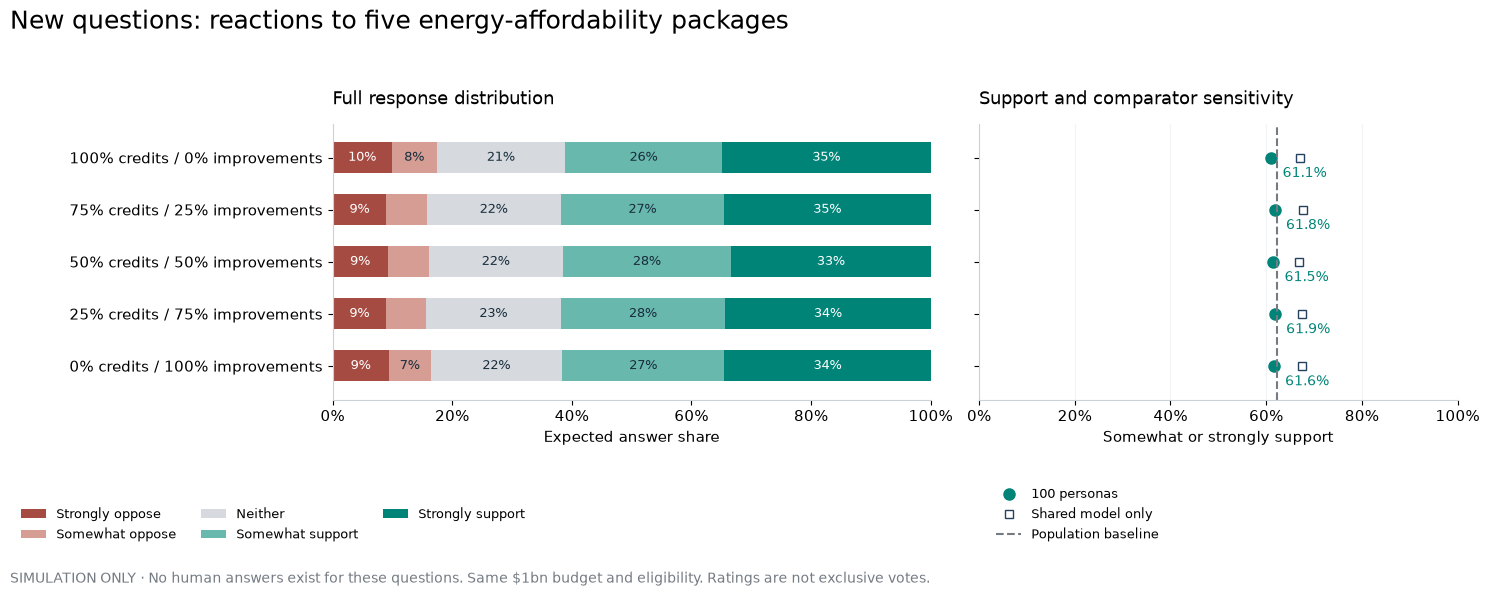

In [4]:
new_labels=[q["short_label"] for q in survey["questions"]]
shares=new_p.mean(0);support=shares[:,3:].sum(-1)
colors=["#A64B42","#D69D94","#D6DADF","#69B8AD","#008477"]
fig,axes=plt.subplots(1,2,figsize=(15,6),gridspec_kw={"width_ratios":[1.25,1]})
ypos=np.arange(5);left=np.zeros(5)
for k,label in enumerate(["Strongly oppose","Somewhat oppose","Neither","Somewhat support","Strongly support"]):
    axes[0].barh(ypos,shares[:,k],left=left,color=colors[k],label=label,height=.6)
    for j in range(5):
        if shares[j,k] >= .07: axes[0].text(left[j]+shares[j,k]/2,j,f"{shares[j,k]:.0%}",ha="center",va="center",fontsize=9,color="white" if k in [0,4] else "#182D3C")
    left+=shares[:,k]
axes[0].set_yticks(ypos,new_labels);axes[0].invert_yaxis();axes[0].set_xlim(0,1)
axes[0].xaxis.set_major_formatter(PercentFormatter(1));axes[0].set_xlabel("Expected answer share")
axes[0].set_title("Full response distribution",loc="left",pad=14)
axes[1].plot(support,ypos,"o",color=TEAL,markersize=8,label="100 personas")
axes[1].plot(new_zero[:,:,3:].sum(-1).mean(0),ypos,"s",color=NAVY,markersize=6,fillstyle="none",label="Shared model only")
axes[1].axvline(new_pop[0,0,3:].sum(),color=GREY,linestyle="--",label="Population baseline")
axes[1].set_yticks(ypos,[]);axes[1].invert_yaxis();axes[1].set_xlim(0,1)
axes[1].xaxis.set_major_formatter(PercentFormatter(1));axes[1].set_xlabel("Somewhat or strongly support")
axes[1].set_title("Support and comparator sensitivity",loc="left",pad=14);axes[1].grid(axis="x",alpha=.6)
for j,value in enumerate(support): axes[1].annotate(f"{value:.1%}",(value,j),xytext=(8,-14),textcoords="offset points",fontsize=10,color=TEAL)
right_handles,right_labels=axes[1].get_legend_handles_labels()
fig.legend(right_handles,right_labels,loc="lower left",bbox_to_anchor=(.67,.075),frameon=False,fontsize=9)
axes[0].set_ylim(4.65,-.65);axes[1].set_ylim(4.65,-.65)
handles,legend_labels=axes[0].get_legend_handles_labels()
fig.legend(handles,legend_labels,loc="lower left",bbox_to_anchor=(.02,.075),ncol=3,frameon=False,fontsize=9)
fig.suptitle("New questions: reactions to five energy-affordability packages",x=.02,ha="left",fontsize=18)
fig.text(.02,.025,"SIMULATION ONLY · No human answers exist for these questions. Same $1bn budget and eligibility. Ratings are not exclusive votes.",fontsize=10,color=GREY)
fig.subplots_adjust(left=.235,right=.985,bottom=.33,top=.79,wspace=.09);save_figure(fig,"08_novel_policy_results")

## Differences between personas
Each heatmap row is one persona and each column is one allocation. Colour is predicted support probability. Rows are sorted by average predicted support only to make patterns readable; this does not define demographic groups.

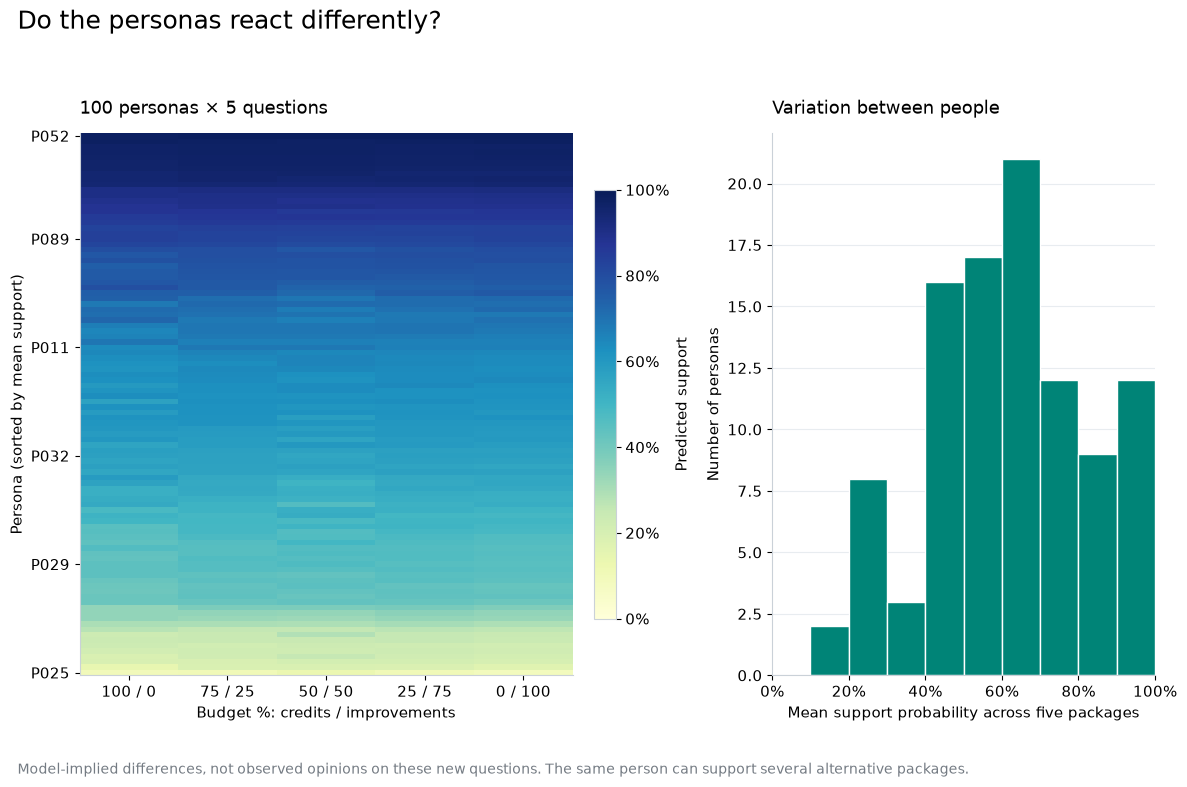

In [5]:
individual_support=new_p[:,:,3:].sum(-1)
order=np.argsort(individual_support.mean(1),kind="stable")[::-1]
fig,axes=plt.subplots(1,2,figsize=(12,8),gridspec_kw={"width_ratios":[1.4,1]})
im=axes[0].imshow(individual_support[order],aspect="auto",vmin=0,vmax=1,cmap="YlGnBu",interpolation="nearest")
axes[0].set_xticks(np.arange(5),["100 / 0","75 / 25","50 / 50","25 / 75","0 / 100"])
axes[0].set_xlabel("Budget %: credits / improvements")
positions=[0,19,39,59,79,99]
axes[0].set_yticks(positions,[ids[order[k]] for k in positions]);axes[0].set_ylabel("Persona (sorted by mean support)")
axes[0].set_title("100 personas × 5 questions",loc="left",pad=14)
fig.colorbar(im,ax=axes[0],fraction=.04,pad=.04,format=PercentFormatter(1),label="Predicted support")
axes[1].hist(individual_support.mean(1),bins=np.linspace(0,1,11),color=TEAL,edgecolor="white")
axes[1].set_xlim(0,1);axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_xlabel("Mean support probability across five packages");axes[1].set_ylabel("Number of personas")
axes[1].set_title("Variation between people",loc="left",pad=14);axes[1].set_axisbelow(True);axes[1].grid(axis="y")
fig.suptitle("Do the personas react differently?",x=.02,ha="left",fontsize=18)
fig.text(.02,.025,"Model-implied differences, not observed opinions on these new questions. The same person can support several alternative packages.",fontsize=10,color=GREY)
fig.tight_layout(rect=(0,.07,1,.94));save_figure(fig,"09_final_persona_variation")
for path,digest in {**seal["input_sha256"],**seal["prediction_sha256"]}.items(): assert sha(path) == digest
save_json("outputs/final_figure_manifest.json",{"exports":exports,"report_sha256":sha("outputs/final_evaluation.json"),"test_predictions_unchanged":True})

## Shareable report
The HTML report embeds the charts and exact survey wording. It also lets you select a persona to inspect that person's predicted support and sampled single-select answers.

In [6]:
def image_tag(name,alt):
    data=base64.b64encode((FIGURES / name).read_bytes()).decode()
    return f'<img src="data:image/png;base64,{data}" alt="{html.escape(alt)}">'
a=results["100 personas"];b=results["Population baseline"];s=results["Shared model only"]
span=float(support.max()-support.min())
ranking=np.argsort(-support)
leader=new_labels[int(ranking[0])]
accuracy_delta=(a["accuracy"]-b["accuracy"])*100
nll_delta=a["nll"]-b["nll"]
metric_rows="".join(f'<tr><td>{html.escape(name)}</td><td>{m["accuracy"]:.1%}</td><td>{m["nll"]:.3f}</td><td>{m["distribution_TV"]:.1%}</td><td>{m["support_share_mae"]*100:.1f} pp</td></tr>' for name,m in results.items())
question_rows="".join(f'<li><b>{html.escape(q["short_label"])}</b><p>{html.escape(q["question_text"].split("Indicated row:\n")[1].split("\n\nAnswer options:")[0])}</p></li>' for q in survey["questions"])
options=" · ".join(o["label"] for o in survey["questions"][0]["options"])
unc=bootstrap["Population baseline"]["accuracy"]["paired_respondent_bootstrap_95"]
llunc=bootstrap["Population baseline"]["nll"]["paired_respondent_bootstrap_95"]
explorer={"labels":new_labels,"options":[o["label"] for o in survey["questions"][0]["options"]],
          "people":[{"id":str(ids[i]),"support":individual_support[i].tolist(),"samples":samples[i].tolist()} for i in range(100)]}
style="""body{font-family:system-ui,-apple-system,sans-serif;color:#203344;background:#f4f7f9;margin:0;line-height:1.6}main{max-width:1120px;margin:auto;padding:48px 24px}h1{font-size:36px;line-height:1.2}h2{font-size:24px;margin-top:40px}p{max-width:950px}img{display:block;width:100%;height:auto;margin:24px 0;background:white;border-radius:8px}section{background:white;padding:24px;margin:24px 0;border:1px solid #dbe3e9;border-radius:12px}.eyebrow{color:#008477;font-weight:700;letter-spacing:.08em;text-transform:uppercase}.cards{display:grid;grid-template-columns:repeat(3,1fr);gap:16px}.card{padding:20px;background:#edf5f5;border-radius:10px}.card b{font-size:28px;display:block}.note{border-left:4px solid #008477;padding:12px 18px;background:#edf5f5}table{width:100%;border-collapse:collapse;font-size:14px}th,td{text-align:left;padding:12px;border-bottom:1px solid #dde5eb}th{color:#244260}select{padding:8px;font-size:16px;margin-left:12px}footer{font-size:13px;color:#697986;margin-top:36px}.muted{color:#697986}@media(max-width:700px){.cards{grid-template-columns:1fr}main{padding:24px 12px}section{padding:12px}table{font-size:12px}th,td{padding:6px}}@media print{body{background:white}main{padding:0}section,img{break-inside:avoid}select{display:none}}"""
body=f"""<!doctype html><html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>100 personas · final simulation</title><style>{style}</style><main>
<div class="eyebrow">Artificial Societies · technical experiment</div><h1>100 learned personas.<br>One energy-affordability decision.</h1>
<p>We fitted a small vector for each of 100 held-out respondents using their existing answers, then predicted responses to three reserved questions and five new policy scenarios.</p>
<div class="cards"><div class="card"><b>100</b>personas, eight learned numbers each</div><div class="card"><b>9,198</b>permitted evidence answers</div><div class="card"><b>500</b>new single-select simulated responses</div></div>
{image_tag('06_final_persona_pipeline.png','Pipeline from known answers to persona vectors and predicted survey answers')}
<section><h2>1. What physically exists?</h2><p><code>final_personas.json</code> contains all 100 vectors and the evidence used to fit them. <code>novel_policy_responses.json</code> contains 500 sampled answers with their full option probabilities. The personas are learned representations of real panel members; no fictional biographies were invented.</p><p>Qwen supplies fixed semantic features. Only eight numbers per new person were fitted. The shared model, PCA, 200 fitting steps and regularization were frozen before final evaluation.</p></section>
<section><h2>2. Accuracy on real, unseen answers</h2><p>We saved the predictions before opening the three reserved energy-policy questions. This checks 300 real answers from the 100 final respondents.</p>
<table><thead><tr><th>Method</th><th>Accuracy ↑</th><th>Log loss ↓</th><th>Distribution error ↓</th><th>Support error ↓</th></tr></thead><tbody>{metric_rows}</tbody></table>
<p class="muted">Distribution error is mean total variation distance. Support error is mean absolute error in the combined support share. Lower is better for both.</p>
{image_tag('07_final_test_results.png','Real answers compared with model and population baseline on the final test')}
<p>The persona model differs from the population baseline by <b>{accuracy_delta:+.1f} percentage points in accuracy</b> and <b>{nll_delta:+.3f} in log loss</b>. We report the result without changing or reselecting the model. Aggregate distribution error remains similar to the population baseline, and the shared-only model has lower support-share error. The improvement is in predicting individual answers; it does not establish better aggregate policy forecasts.</p>
<p>Paired respondent-bootstrap 95% interval for the accuracy difference: {unc[0]*100:+.1f} to {unc[1]*100:+.1f} percentage points; for log loss: {llunc[0]:+.3f} to {llunc[1]:+.3f}. These describe people on three fixed questions, not generalization to arbitrary policies or uncertainty from model selection.</p></section>
<section><h2>3. The decision and five new questions</h2><p><b>Decision:</b> which budget allocations should advance to a real human pilot survey?</p><p>{html.escape(survey['scenario'])}</p><p>For each package, ask: <b>Would you support or oppose...</b></p><ol>{question_rows}</ol><p><b>Single-select options:</b> {html.escape(options)}.</p>
{image_tag('08_novel_policy_results.png','Predicted answer distributions for five budget allocations')}
<p class="note"><b>Simulation only.</b> There are no human answers to these five new questions. The predicted support range is {support.min():.1%}–{support.max():.1%}, a {span*100:.1f} percentage-point spread. The numerically highest package is {html.escape(leader)}; this does not establish a winning policy. The model barely distinguishes the allocations; differences are smaller than its measured support-share error on the reserved questions, although that error is not a confidence interval for this new survey.</p>
<p>Use these outputs to formulate hypotheses and design a pilot. Approval of several packages is possible; the survey does not measure exclusive preference between them. Headline shares average probabilities. The 500 sampled answers are one reproducible draw, not additional evidence.</p></section>
<section><h2>4. Explore the 100 personas</h2>{image_tag('09_final_persona_variation.png','Heatmap of predicted support for each of 100 personas')}
<label for="persona">Select a persona</label><select id="persona"></select><table><thead><tr><th>Allocation</th><th>Predicted support</th><th>One sampled answer</th></tr></thead><tbody id="personRows"></tbody></table>
<p class="muted">Support is the sum of somewhat and strongly support probabilities. These are model-implied differences, not observed new-policy opinions.</p></section>
<section><h2>5. What this supports</h2><p>A complete, reproducible demonstration: real evidence → 100 learned representations → new-question predictions → a frozen human-answer evaluation. Personalization had mixed validation results, so the common population prediction remains an essential comparator.</p><p>For a consequential decision, collect real answers to these five packages and test whether the model correctly predicts differences between them. This historical U.S. Prolific panel is not population weighted and does not establish 2027 public opinion. Related policy questions share an instrument; public-model pretraining contamination cannot be ruled out.</p></section>
<footer>Built from the pinned Twin-2K-500 dataset (CC BY 4.0). See README for attribution. Exact inputs, hashes and evaluation rules are recorded in final_prediction_seal.json, final_evaluation.json and configs/final_simulation_protocol.json. All charts are also available as PNG and PDF.</footer>
<script type="application/json" id="explorerData">{json.dumps(explorer).replace('<','&lt;')}</script>
<script>const data=JSON.parse(document.getElementById('explorerData').textContent);const select=document.getElementById('persona');data.people.forEach(p=>{{const o=document.createElement('option');o.value=p.id;o.textContent=p.id;select.appendChild(o)}});function render(){{const p=data.people.find(p=>p.id===select.value);const tbody=document.getElementById('personRows');tbody.replaceChildren();data.labels.forEach((label,i)=>{{const tr=document.createElement('tr');[label,(100*p.support[i]).toFixed(1)+'%',data.options[p.samples[i]-1]].forEach(value=>{{const td=document.createElement('td');td.textContent=value;tr.appendChild(td)}});tbody.appendChild(tr)}})}}select.addEventListener('change',render);render();</script></main></html>"""
(OUT / "final_simulation_report.html").write_text(body)
print("Saved outputs/final_simulation_report.html with embedded charts and a 100-persona explorer.")

Saved outputs/final_simulation_report.html with embedded charts and a 100-persona explorer.


## What to take away
- **Individual answers:** 46.3% exact accuracy versus 32.3% for the population baseline; log loss 1.301 versus 1.431.
- **Aggregate opinions:** distribution error is similar to the baseline. Personas underestimate support by 7.0 percentage points on average; the shared-only comparator has lower support-share error.
- **New decision:** predicted support is 61.1–61.9% across all five packages. The simulation does not identify a credible winner. These questions need human validation.

The validation and final tests contain different questions and people. Their accuracy percentages are not a before/after training comparison. No fitting or reselection followed the final test.